In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/flights.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (336776, 21)


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


In [2]:
df.info()

print("Duplicate rows:", df.duplicated().sum())

quality = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})

display(quality.sort_values("Missing Percentage", ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              336776 non-null  int64  
 1   year            336776 non-null  int64  
 2   month           336776 non-null  int64  
 3   day             336776 non-null  int64  
 4   dep_time        328521 non-null  float64
 5   sched_dep_time  336776 non-null  int64  
 6   dep_delay       328521 non-null  float64
 7   arr_time        328063 non-null  float64
 8   sched_arr_time  336776 non-null  int64  
 9   arr_delay       327346 non-null  float64
 10  carrier         336776 non-null  str    
 11  flight          336776 non-null  int64  
 12  tailnum         334264 non-null  str    
 13  origin          336776 non-null  str    
 14  dest            336776 non-null  str    
 15  air_time        327346 non-null  float64
 16  distance        336776 non-null  int64  
 17  hour            33677

,Missing Count,Missing Percentage,Data Type
arr_delay,9430,2.80,float64
air_time,9430,2.80,float64
arr_time,8713,2.59,float64
dep_time,8255,2.45,float64
dep_delay,8255,2.45,float64
tailnum,2512,0.75,str
id,0,0.00,int64
origin,0,0.00,str
time_hour,0,0.00,str
minute,0,0.00,int64


In [3]:
df["delayed"] = np.where(
    df["arr_delay"].notna(),
    (df["arr_delay"] >= 15).astype(int),
    np.nan
)

labeled = df.dropna(subset=["delayed"]).copy()
labeled["delayed"] = labeled["delayed"].astype(int)

print("Total flights:", len(df))
print("Flights with known arrival delay:", len(labeled))
print("Flights without arrival delay:", df["arr_delay"].isna().sum())
print("\nTarget distribution:")
display(labeled["delayed"].value_counts().rename(
    index={0: "Not substantially delayed", 1: "Substantially delayed"}
))

Total flights: 336776
Flights with known arrival delay: 327346
Flights without arrival delay: 9430

Target distribution:


delayed
Not substantially delayed    247246
Substantially delayed         80100
Name: count, dtype: int64

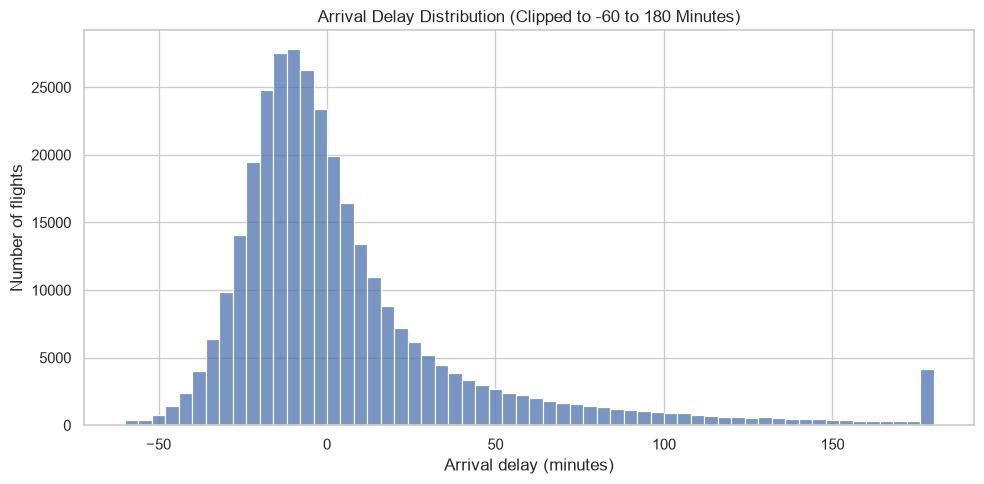

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(labeled["arr_delay"].clip(-60, 180), bins=60)
plt.title("Arrival Delay Distribution (Clipped to -60 to 180 Minutes)")
plt.xlabel("Arrival delay (minutes)")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.show()

Flights delayed by at least 15 minutes: 24.47%


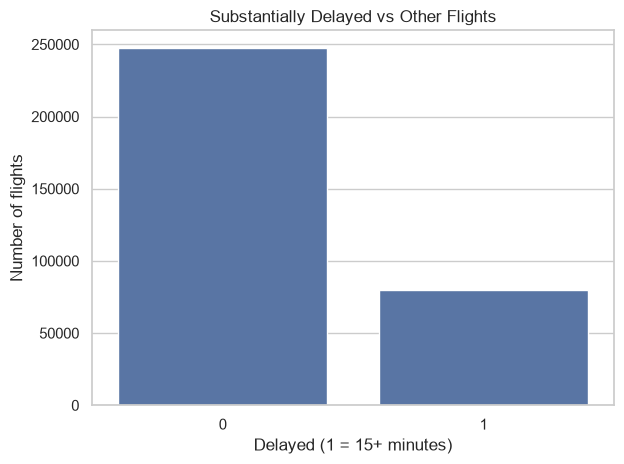

In [5]:
delay_rate = labeled["delayed"].mean() * 100

print(f"Flights delayed by at least 15 minutes: {delay_rate:.2f}%")

sns.countplot(data=labeled, x="delayed")
plt.title("Substantially Delayed vs Other Flights")
plt.xlabel("Delayed (1 = 15+ minutes)")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.show()

,total_flights,delay_rate,avg_arr_delay
name,,,
Frontier Airlines Inc.,681,38.77,21.92
AirTran Airways Corporation,3175,34.65,20.12
Mesa Airlines Inc.,544,32.90,15.56
ExpressJet Airlines Inc.,51108,32.09,15.80
Envoy Air,25037,27.90,10.77
JetBlue Airways,54049,26.95,9.46
Southwest Airlines Co.,12044,25.69,9.65
Endeavor Air Inc.,17294,25.57,7.38
SkyWest Airlines Inc.,29,24.14,11.93


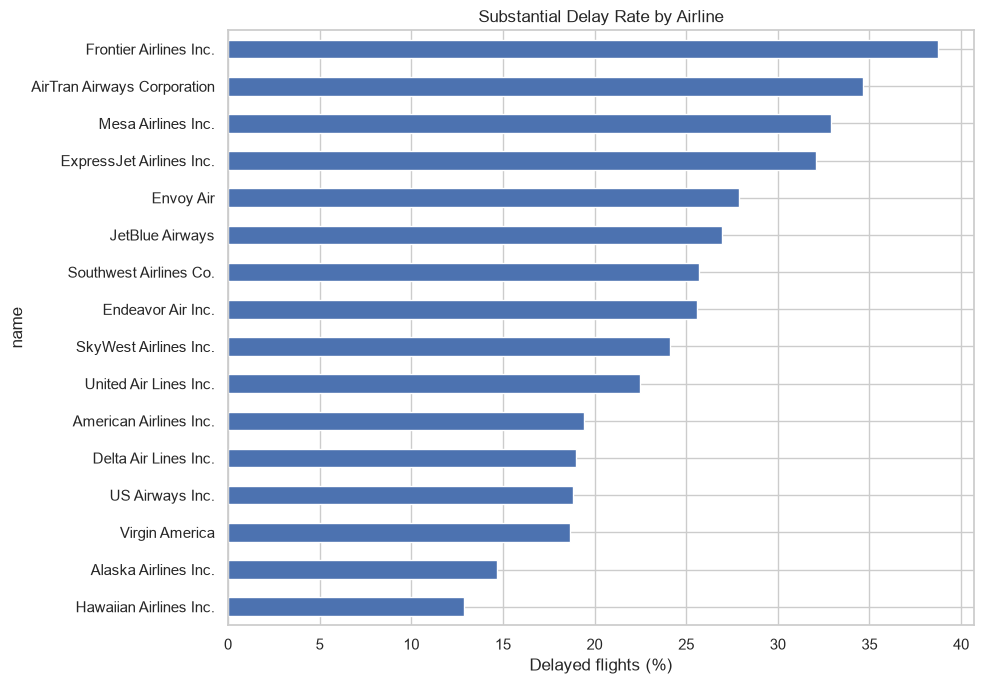

In [8]:
airline_delay = (
    labeled.groupby("name")
    .agg(
        total_flights=("delayed", "size"),
        delay_rate=("delayed", "mean"),
        avg_arr_delay=("arr_delay", "mean")
    )
    .sort_values("delay_rate", ascending=False)
)

airline_delay["delay_rate"] *= 100

display(airline_delay.round(2))

airline_delay["delay_rate"].sort_values().plot(
    kind="barh", figsize=(10, 7)
)
plt.title("Substantial Delay Rate by Airline")
plt.xlabel("Delayed flights (%)")
plt.tight_layout()
plt.show()

,total_flights,delay_rate,avg_arr_delay
name,,,
Frontier Airlines Inc.,681,38.77,21.92
AirTran Airways Corporation,3175,34.65,20.12
Mesa Airlines Inc.,544,32.90,15.56
ExpressJet Airlines Inc.,51108,32.09,15.80
Envoy Air,25037,27.90,10.77
JetBlue Airways,54049,26.95,9.46
Southwest Airlines Co.,12044,25.69,9.65
Endeavor Air Inc.,17294,25.57,7.38
SkyWest Airlines Inc.,29,24.14,11.93


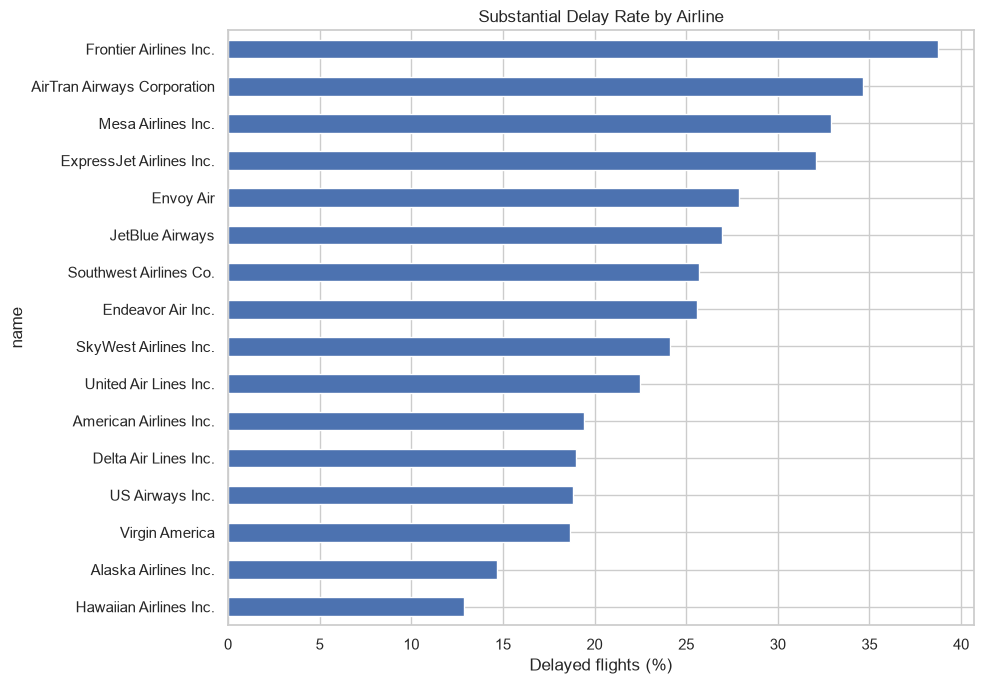

,total_flights,delay_rate,avg_arr_delay
origin,,,
EWR,117127,26.34,9.11
JFK,109079,23.70,5.55
LGA,101140,23.14,5.78


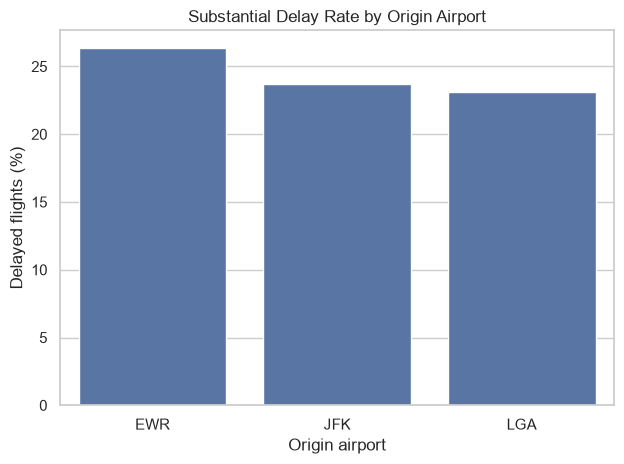

In [9]:
airport_delay = (
    labeled.groupby("origin")
    .agg(
        total_flights=("delayed", "size"),
        delay_rate=("delayed", "mean"),
        avg_arr_delay=("arr_delay", "mean")
    )
)

airport_delay["delay_rate"] *= 100

display(airport_delay.round(2))

sns.barplot(data=airport_delay.reset_index(), x="origin", y="delay_rate")
plt.title("Substantial Delay Rate by Origin Airport")
plt.xlabel("Origin airport")
plt.ylabel("Delayed flights (%)")
plt.tight_layout()
plt.show()

,total_flights,delay_rate,avg_arr_delay
month,,,
1,26398,23.49,6.13
2,23611,23.78,5.61
3,27902,23.60,5.81
4,27564,28.75,11.18
5,28128,22.67,3.52
6,27075,31.52,16.48
7,28293,32.21,16.71
8,28756,24.60,6.04
9,27010,13.72,-4.02


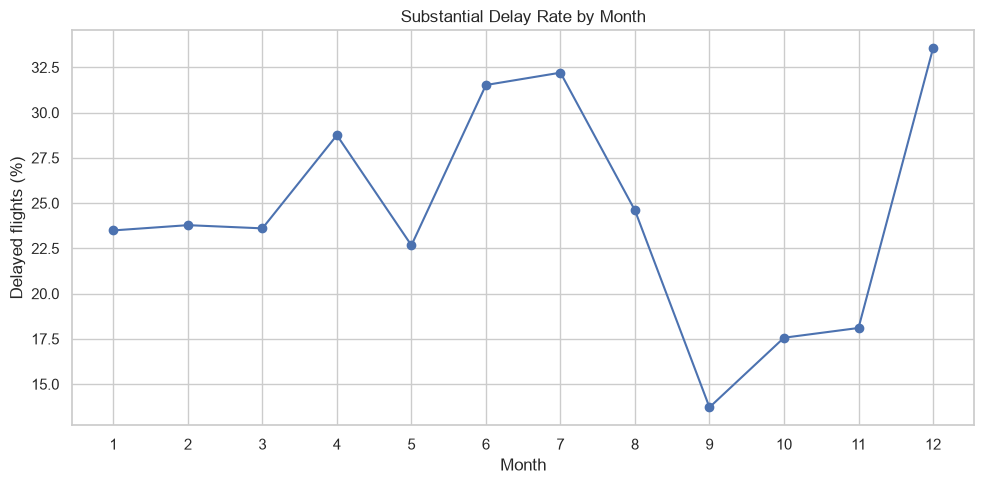

In [10]:
monthly_delay = labeled.groupby("month").agg(
    total_flights=("delayed", "size"),
    delay_rate=("delayed", "mean"),
    avg_arr_delay=("arr_delay", "mean")
)

monthly_delay["delay_rate"] *= 100

display(monthly_delay.round(2))

monthly_delay["delay_rate"].plot(
    marker="o", figsize=(10, 5)
)
plt.title("Substantial Delay Rate by Month")
plt.xlabel("Month")
plt.ylabel("Delayed flights (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

,total_flights,delay_rate,avg_arr_delay
hour,,,
5,1940,10.46,-4.80
6,25447,11.88,-3.38
7,22475,12.03,-5.30
8,26734,16.35,-1.11
9,19931,17.09,-1.45
10,16370,18.49,0.95
11,15689,18.53,1.48
12,17744,20.69,3.49
13,19457,23.67,6.54


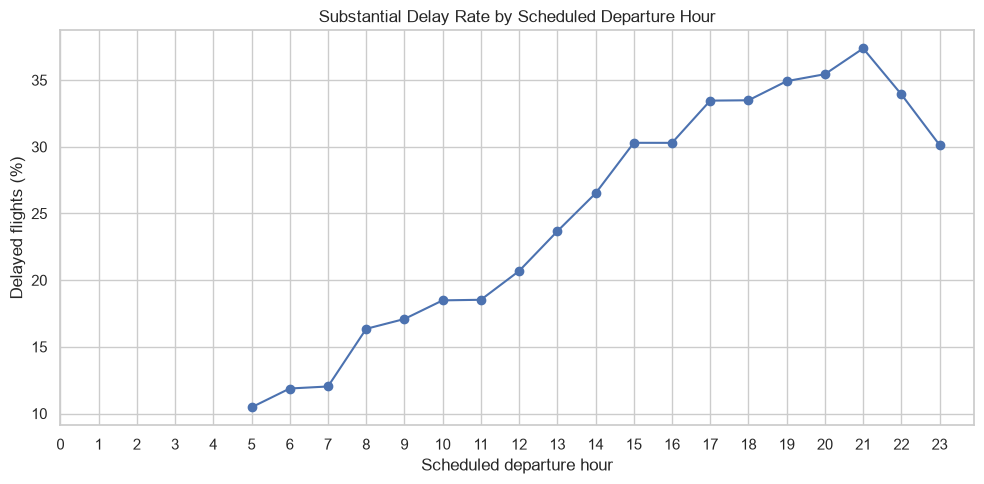

In [11]:
hourly_delay = labeled.groupby("hour").agg(
    total_flights=("delayed", "size"),
    delay_rate=("delayed", "mean"),
    avg_arr_delay=("arr_delay", "mean")
)

hourly_delay["delay_rate"] *= 100

display(hourly_delay.round(2))

hourly_delay["delay_rate"].plot(
    marker="o", figsize=(10, 5)
)
plt.title("Substantial Delay Rate by Scheduled Departure Hour")
plt.xlabel("Scheduled departure hour")
plt.ylabel("Delayed flights (%)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

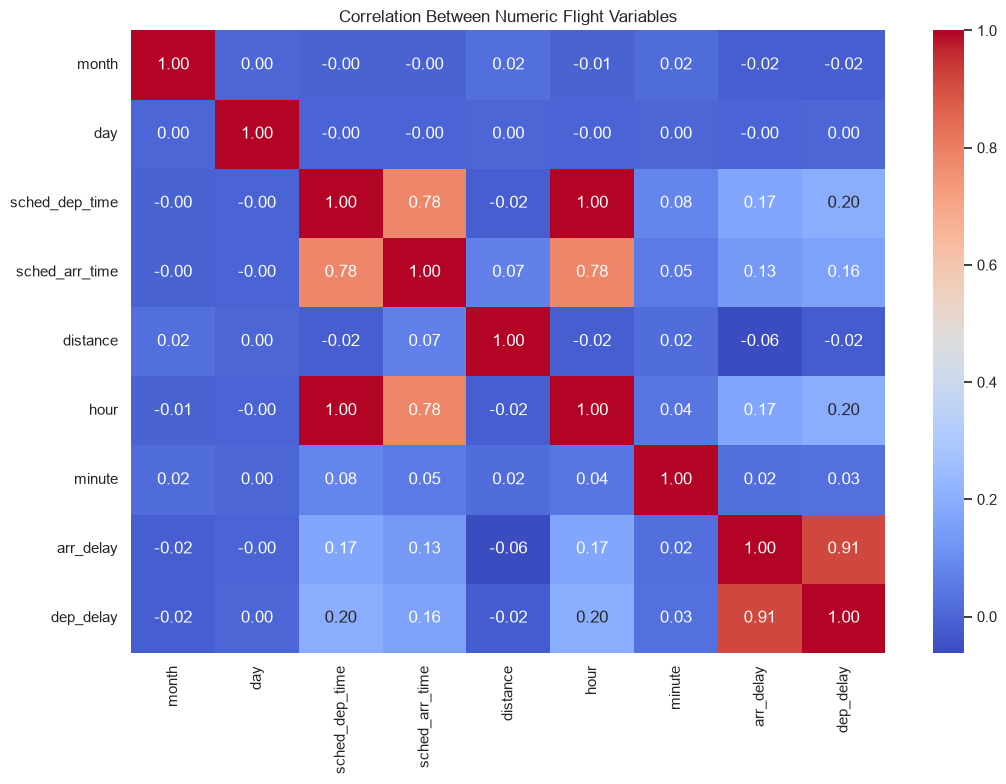

In [12]:
numeric_cols = [
    "month", "day", "sched_dep_time", "sched_arr_time",
    "distance", "hour", "minute", "arr_delay", "dep_delay"
]

plt.figure(figsize=(11, 8))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numeric Flight Variables")
plt.tight_layout()
plt.show()